# <u> **V. Regression project: Boston Housing** </u>

In [44]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

## Task 1: Familiarize Yourself with the Dataset



In [3]:
housing_df = pd.read_csv('boston_housing.csv')

#1. Display the first 5 rows of the dataset.

housing_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [4]:
# 2. Display the data types of each column.
print(housing_df.dtypes)

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object


In [5]:
# 3.Check for missing values in each column.
housing_df.isnull()


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,False,False,False,False,False,False,False,False,False,False,False,False,False,False
502,False,False,False,False,False,False,False,False,False,False,False,False,False,False
503,False,False,False,False,False,False,False,False,False,False,False,False,False,False
504,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [6]:
# 4. Check for duplicate rows.
housing_df.duplicated()


0      False
1      False
2      False
3      False
4      False
       ...  
501    False
502    False
503    False
504    False
505    False
Length: 506, dtype: bool

In [7]:
# 5. Display the correlation matrix of the dataset.
housing_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


## Task 2: Generate Descriptive Statistics and Visualizations


In [8]:
# 1. Display descriptive statistics of the dataset.
housing_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


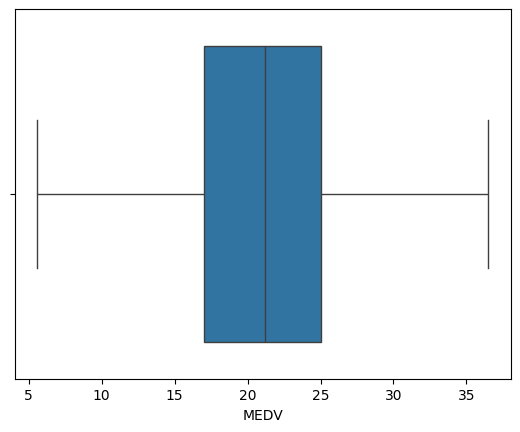

In [11]:
# 2.Create a boxplot for MEDV (Median value of owner-occupied homes).
sns.boxplot(x = housing_df['MEDV'], showfliers=False) # showfiliers pour supprimer les circles
plt.show()


<Axes: xlabel='CHAS', ylabel='count'>

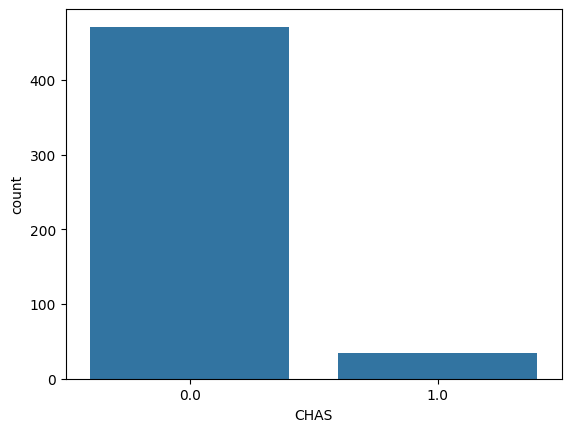

In [22]:
# 3. Create a bar plot for CHAS (Charles River dummy variable).
sns.countplot(x='CHAS', data=housing_df) 
# countplot() compte automatiquement le nombre d'apparitions (la fréquence), concue pour les variables qualitatives nominales.


<Axes: xlabel='CHAS'>

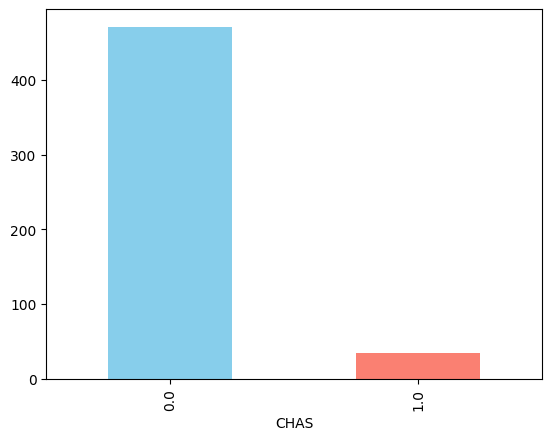

In [23]:
# methode alternative de countplot()
counts = housing_df['CHAS'].value_counts()

counts.plot(kind='bar', color=['skyblue', 'salmon'])

<Axes: xlabel='AGE_GROUPE', ylabel='MEDV'>

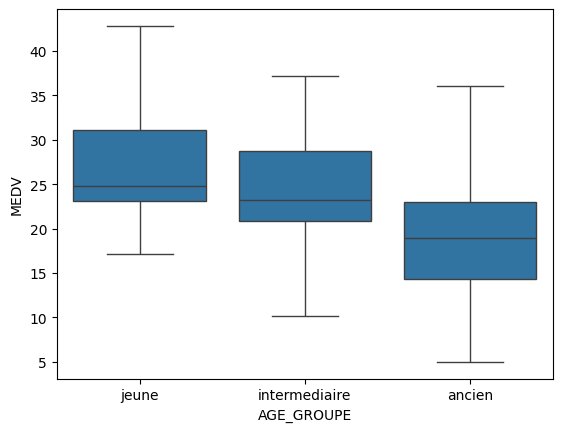

In [51]:
# 4. Discretize AGE into three groups and create a boxplot of MEDV versus these groups:
housing_df['AGE_GROUPE'] = pd.cut(housing_df['AGE'], bins = [0,30,60,100], labels = ['jeune', 'intermediaire', 'ancien'])
sns.boxplot(x = 'AGE_GROUPE', y = 'MEDV', data = housing_df, showfliers=False)

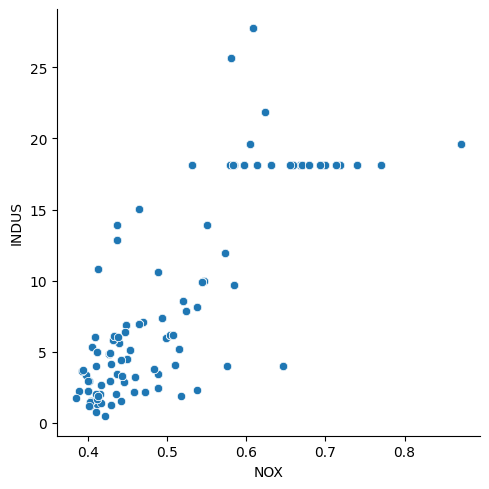

In [42]:
# 5. Create a scatter plot showing the relationship between NOX (nitric oxide concentrations) and INDUS (non-retail business acres).
sns.relplot(x = 'NOX', y = 'INDUS', kind = 'scatter', data = housing_df)



<Axes: xlabel='PTRATIO', ylabel='Count'>

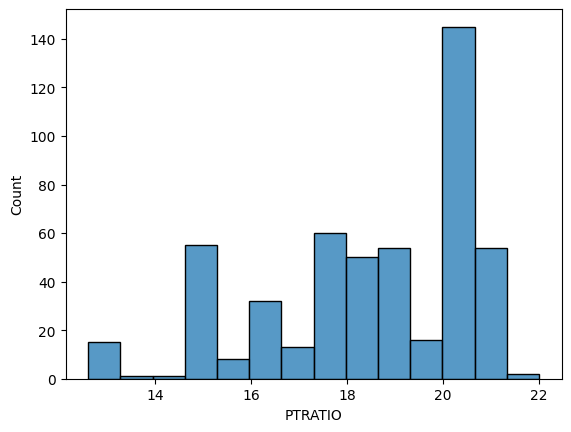

In [43]:
# 6. Create a histogram for PTRATIO (pupil-teacher ratio).
sns.histplot(data = housing_df, x = 'PTRATIO')

## Task 3: Apply Statistical Tests


In [48]:
# 1. Use Levene’s test to check if the variances of MEDV for homes bounded by the Charles River (CHAS = 1) and those not bounded (CHAS = 0) are equal.
stats.levene(housing_df[housing_df['CHAS']==1]['MEDV'], housing_df[housing_df['CHAS']==0]['MEDV'], center = 'mean')

LeveneResult(statistic=np.float64(8.75190489604598), pvalue=np.float64(0.003238119367639829))

In [52]:
# 2.Conduct an ANOVA test to compare MEDV among the three AGE groups created earlier.
grp_1 = housing_df[housing_df['AGE_GROUPE']=='jeune']['MEDV']
grp_2 = housing_df[housing_df['AGE_GROUPE']=='intermediaire']['MEDV']
grp_3 = housing_df[housing_df['AGE_GROUPE']=='ancien']['MEDV']


f_statistique, p_value = stats.f_oneway(grp_1, grp_2, grp_3)
print(
    "F_statistique:{0} , P_value:{1}".format(f_statistique,p_value)
)


F_statistique:28.022628828406628 , P_value:2.893582414484241e-12


In [55]:
# 4. Perform a Pearson correlation test to assess the relationship between NOX and INDUS.
stats.pearsonr(housing_df['NOX'], housing_df['INDUS'])

PearsonRResult(statistic=np.float64(0.763651446920915), pvalue=np.float64(7.913361061241532e-98))

In [56]:
# 5. Fit a simple linear regression model to evaluate the impact of DIS (distance to employment centres) on MEDV.
x = housing_df[['DIS']]
y = housing_df['MEDV']

x = sm.add_constant(x)

model = sm.OLS(y,x).fit()
prediction = model.predict(x)

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        19:23:16   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.000      16.784      19.996
DIS            1.0916      0.188      5.795      0.000       0.722       1.462
==============================================================================
Omnibus:                      139.779   Durbin-Watson:                   0.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              305.104
Skew:                           1.466   Prob(JB):                     5.59e-67
Kurtosis:                       5.424   Cond. No.                         9.32
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""


**Regression Report**

A simple linear regression was conducted to evaluate the impact of the distance to employment centers (DIS) on the median value of owner-occupied homes (MEDV).
• Model Fit: R² = 0.062, F(1, 504) = 33.58, p < 0.001  
• Intercept (β₀): 18.390, p < 0.001  
• DIS Coefficient (β₁): 1.0916, t = 5.79, p < 0.001  

**Interpretation**

1. Statistical Significance: The predictor variable DIS is statistically significant (p < 0.001), meaning that the distance to employment centers has a real, non-random impact on housing prices.
2. Direction and Magnitude: The relationship is positive. For each additional unit increase in distance to employment centers (DIS), the median value of a home (MEDV) increases by approximately $1,092 (β₁ = 1.0916).
3. Variance Explained: The R² of 0.062 indicates that DIS accounts for only 6.2% of the variance in home values. While the relationship is highly significant, distance alone is a weak predictor, suggesting that other crucial factors (e.g., crime rates, room counts) should be added to a multiple regression model to improve predictive power.